In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/PhD/Big Data Final Project"

if os.path.exists(PROJECT_DIR):
    print("Success! Project folder found.")
    print("Project location:", PROJECT_DIR)
else:
    print("Folder not found. We need to check the Drive path.")

Success! Project folder found.
Project location: /content/drive/MyDrive/PhD/Big Data Final Project


In [3]:
!pip install pyspark

In [4]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Big Data Final Project")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

print("Spark Session Created Successfully!")
print("Spark Version:", spark.version)

Spark Session Created Successfully!
Spark Version: 4.0.5


In [6]:

import os
import csv

# Project data folders
RAW_DIR = os.path.join(PROJECT_DIR, "02_Data", "Raw")
os.makedirs(RAW_DIR, exist_ok=True)

# 1. Customer master data
customers = [
    [101, "Asha", "Jaipur"],
    [102, "Ravi", "Delhi"],
    [103, "Meera", "Mumbai"],
    [104, "Arjun", "Pune"],
    [105, "Priya", "Jaipur"],
    [106, "Karan", "Bengaluru"]
]

# 2. Product master data
products = [
    [201, "Laptop", "Electronics", 55000],
    [202, "Mobile", "Electronics", 25000],
    [203, "Chair", "Furniture", 4500],
    [204, "Desk", "Furniture", 8000],
    [205, "Headphones", "Accessories", 2000],
    [206, "Keyboard", "Accessories", 1500]
]

# 3. First batch: original orders
orders_batch_1 = [
    [1001, 101, 201, "2026-01-05", 1, 55000, 0.10, "Placed", "2026-01-05 10:00:00"],
    [1002, 102, 202, "2026-01-06", 2, 25000, 0.05, "Placed", "2026-01-06 11:00:00"],
    [1003, 103, 203, "2026-01-07", 1, 4500, 0.00, "Shipped", "2026-01-07 12:00:00"],
    [1004, 104, 204, "2026-01-08", -1, 8000, 0.05, "Placed", "2026-01-08 13:00:00"],
    [1005, 105, 205, "2026-01-09", 2, 2000, 0.10, "Placed", "2026-01-09 14:00:00"],
    [1006, 106, 206, "2026-01-10", 3, 1500, 0.00, "Delivered", "2026-01-10 15:00:00"],
    [1007, "", 201, "2026-01-11", 1, 55000, 0.05, "Placed", "2026-01-11 10:00:00"],
    [1008, 102, 203, "2026-01-12", 2, 4500, 0.15, "Shipped", "2026-01-12 11:00:00"],
    [1009, 103, 204, "2026-01-13", 1, 8000, 0.00, "Placed", "2026-01-13 12:00:00"],
    [1010, 104, 205, "2026-01-14", 1, 2000, 1.25, "Placed", "2026-01-14 13:00:00"],
    [1011, 105, 206, "2026-01-15", 2, 1500, 0.05, "Delivered", "2026-01-15 14:00:00"],
    [1012, 106, 201, "01/16/2026", 1, 55000, 0.10, " placed ", "2026-01-16 15:00:00"],
    [1013, 101, 202, "2026-01-17", 1, 25000, 0.00, "Shipped", "2026-01-17 10:00:00"],
    [1014, 102, 205, "2026-01-18", 2, 2000, 0.10, "Delivered", "2026-01-18 11:00:00"],
    [1015, 103, 206, "2026-01-19", 1, 1500, 0.00, "Placed", "2026-01-19 12:00:00"]
]

# Add one deliberate duplicate record
orders_batch_1.append(orders_batch_1[0].copy())

# 4. Second batch: new orders and updates to earlier orders
orders_batch_2 = [
    [1016, 104, 201, "2026-02-01", 1, 55000, 0.05, "Placed", "2026-02-01 10:00:00"],
    [1017, 105, 202, "2026-02-02", 1, 25000, 0.10, "Placed", "2026-02-02 11:00:00"],
    [1018, 106, 203, "2026-02-03", 2, 4500, 0.00, "Shipped", "2026-02-03 12:00:00"],
    [1019, 101, 204, "2026-02-04", 1, 8000, 0.05, "Placed", "2026-02-04 13:00:00"],
    [1020, 102, 206, "2026-02-05", 2, 1500, 0.00, "Placed", "2026-02-05 14:00:00"],

    # Updates to three earlier orders
    [1002, 102, 202, "2026-01-06", 2, 25000, 0.05, "Delivered", "2026-02-06 10:00:00"],
    [1005, 105, 205, "2026-01-09", 2, 2000, 0.10, "Shipped", "2026-02-06 11:00:00"],
    [1008, 102, 203, "2026-01-12", 2, 4500, 0.15, "Delivered", "2026-02-06 12:00:00"]
]

# Helper function to write CSV files
def write_csv(filename, headers, rows):
    path = os.path.join(RAW_DIR, filename)
    with open(path, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(headers)
        writer.writerows(rows)
    print("Created:", filename, "| Rows:", len(rows))

# Write customer and product files
write_csv(
    "customers.csv",
    ["customer_id", "customer_name", "city"],
    customers
)

write_csv(
    "products.csv",
    ["product_id", "product_name", "category", "unit_price"],
    products
)

# Write two order batches
order_headers = [
    "order_id", "customer_id", "product_id", "order_date",
    "quantity", "unit_price", "discount", "status", "last_updated"
]

write_csv("orders_batch_1.csv", order_headers, orders_batch_1)
write_csv("orders_batch_2.csv", order_headers, orders_batch_2)

print("\nAll source datasets created successfully!")


Created: customers.csv | Rows: 6
Created: products.csv | Rows: 6
Created: orders_batch_1.csv | Rows: 16
Created: orders_batch_2.csv | Rows: 8

All source datasets created successfully!


In [7]:
# List all files available in our Raw data directory
print("Files in Raw Data folder:")

for filename in os.listdir(RAW_DIR):
    print(filename)

Files in Raw Data folder:
customers.csv
products.csv
orders_batch_1.csv
orders_batch_2.csv


## 3. Introducing Data Quality Issues

Real-world datasets may contain incomplete, duplicated or invalid records. To demonstrate data-quality handling in our ETL pipeline, the synthetic order dataset includes selected data-quality issues.

These include:
- A duplicate order record.
- A missing customer ID.
- A missing order ID.
- A negative order quantity.
- An invalid discount value.
- Inconsistent date formatting.
- Extra whitespace in an order status.

These issues are introduced intentionally so that the Silver layer can demonstrate data validation, cleaning and standardisation.

In [8]:
# Create one order record with a deliberately missing order ID
missing_id_order = [
    "", 106, 202, "2026-01-20", 1, 25000,
    0.05, "Placed", "2026-01-20 13:00:00"
]

# Add this record to the first batch
orders_batch_1.append(missing_id_order)

# Rewrite the first batch CSV with the additional record
write_csv("orders_batch_1.csv", order_headers, orders_batch_1)

print("Missing order ID test record added successfully.")

Created: orders_batch_1.csv | Rows: 17
Missing order ID test record added successfully.


## 4. Bronze Layer – Raw Data Ingestion

### Objective

The objective of the Bronze Layer is to ingest source data into the Data Lake while retaining the original records and their structure as much as possible.

### Technology Used

Apache PySpark is used to read the CSV source files and store them in Parquet format.

### Why Parquet?

Parquet is a column-oriented storage format. It supports efficient storage and data retrieval, making it suitable for analytical workloads.

### Processing Steps

1. Read customer, product and order CSV files.
2. Load the records into Spark DataFrames.
3. Add ingestion metadata for tracking the source and batch.
4. Store the ingested data in the Bronze directory in Parquet format.

The Bronze Layer does not perform business-level data cleaning. Data-quality validation and cleaning will be addressed in the Silver Layer.

In [9]:
# Read the customer CSV file using Apache Spark

customers_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(os.path.join(RAW_DIR, "customers.csv"))
)

# Display the first five records
customers_df.show(5)

# Display the structure and data types
customers_df.printSchema()

+-----------+-------------+------+
|customer_id|customer_name|  city|
+-----------+-------------+------+
|        101|         Asha|Jaipur|
|        102|         Ravi| Delhi|
|        103|        Meera|Mumbai|
|        104|        Arjun|  Pune|
|        105|        Priya|Jaipur|
+-----------+-------------+------+
only showing top 5 rows
root
 |-- customer_id: integer (nullable = true)
 |-- customer_name: string (nullable = true)
 |-- city: string (nullable = true)



## 5. Loading Product and Order Data into Spark

In this stage, the product master data and two batches of order transaction data are loaded into Spark DataFrames.

The product data contains product identifiers, names, categories and prices. The order data contains customer purchases and transaction updates.

Both order batches are loaded separately because they will later be used to demonstrate full-refresh and incremental ETL processing.

In [10]:
# Read product master data into a Spark DataFrame
products_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(os.path.join(RAW_DIR, "products.csv"))
)

# Read the first batch of orders
orders_batch_1_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(os.path.join(RAW_DIR, "orders_batch_1.csv"))
)

# Read the second batch of orders
orders_batch_2_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(os.path.join(RAW_DIR, "orders_batch_2.csv"))
)

# Count the records in each DataFrame
print("Customers:", customers_df.count())
print("Products:", products_df.count())
print("Orders - Batch 1:", orders_batch_1_df.count())
print("Orders - Batch 2:", orders_batch_2_df.count())

Customers: 6
Products: 6
Orders - Batch 1: 17
Orders - Batch 2: 8


## 6. Initial Inspection of Order Data

The two order batches are inspected separately to understand their structure, column names, data types and record-level characteristics.

This inspection helps identify potential data-quality issues before the data is stored in the Bronze Layer.

In [11]:
# Display the first 10 records from Batch 1
orders_batch_1_df.show(10, truncate=False)

# Display the schema of Batch 1
orders_batch_1_df.printSchema()

+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+
|order_id|customer_id|product_id|order_date|quantity|unit_price|discount|status   |last_updated       |
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+
|1001    |101        |201       |2026-01-05|1       |55000     |0.1     |Placed   |2026-01-05 10:00:00|
|1002    |102        |202       |2026-01-06|2       |25000     |0.05    |Placed   |2026-01-06 11:00:00|
|1003    |103        |203       |2026-01-07|1       |4500      |0.0     |Shipped  |2026-01-07 12:00:00|
|1004    |104        |204       |2026-01-08|-1      |8000      |0.05    |Placed   |2026-01-08 13:00:00|
|1005    |105        |205       |2026-01-09|2       |2000      |0.1     |Placed   |2026-01-09 14:00:00|
|1006    |106        |206       |2026-01-10|3       |1500      |0.0     |Delivered|2026-01-10 15:00:00|
|1007    |NULL       |201       |2026-01-11|1       |55000     |

In [12]:
# Display all records from the second order batch
orders_batch_2_df.show(20, truncate=False)

# Display the structure of the second batch
orders_batch_2_df.printSchema()

+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+
|order_id|customer_id|product_id|order_date|quantity|unit_price|discount|status   |last_updated       |
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+
|1016    |104        |201       |2026-02-01|1       |55000     |0.05    |Placed   |2026-02-01 10:00:00|
|1017    |105        |202       |2026-02-02|1       |25000     |0.1     |Placed   |2026-02-02 11:00:00|
|1018    |106        |203       |2026-02-03|2       |4500      |0.0     |Shipped  |2026-02-03 12:00:00|
|1019    |101        |204       |2026-02-04|1       |8000      |0.05    |Placed   |2026-02-04 13:00:00|
|1020    |102        |206       |2026-02-05|2       |1500      |0.0     |Placed   |2026-02-05 14:00:00|
|1002    |102        |202       |2026-01-06|2       |25000     |0.05    |Delivered|2026-02-06 10:00:00|
|1005    |105        |205       |2026-01-09|2       |2000      |

In [13]:
# Define the Bronze layer storage directory
BRONZE_DIR = os.path.join(
    PROJECT_DIR,
    "03_Data_Lake",
    "Bronze"
)

# Create the Bronze directory if it does not exist
os.makedirs(BRONZE_DIR, exist_ok=True)

# Display the storage location
print("Bronze Layer Location:", BRONZE_DIR)

# Check whether the directory exists
print("Bronze directory exists:", os.path.exists(BRONZE_DIR))

Bronze Layer Location: /content/drive/MyDrive/PhD/Big Data Final Project/03_Data_Lake/Bronze
Bronze directory exists: True


### Writing Customer Data to the Bronze Layer

The customer Spark DataFrame is stored in Parquet format in the Bronze Layer.

The original CSV file remains unchanged in the Raw directory. This creates a separate, structured storage copy for subsequent data processing.

In [14]:
# Write the customer DataFrame in Parquet format
customers_df.write \
    .mode("overwrite") \
    .parquet(os.path.join(BRONZE_DIR, "customers"))

print("Customer data successfully written to Bronze.")

Customer data successfully written to Bronze.


In [15]:
# Read the customer data from Bronze in Parquet format
bronze_customers_df = spark.read.parquet(
    os.path.join(BRONZE_DIR, "customers")
)

# Display the stored records
bronze_customers_df.show()

# Display the stored schema
bronze_customers_df.printSchema()

# Verify the number of records
print("Bronze customer count:", bronze_customers_df.count())

+-----------+-------------+---------+
|customer_id|customer_name|     city|
+-----------+-------------+---------+
|        101|         Asha|   Jaipur|
|        102|         Ravi|    Delhi|
|        103|        Meera|   Mumbai|
|        104|        Arjun|     Pune|
|        105|        Priya|   Jaipur|
|        106|        Karan|Bengaluru|
+-----------+-------------+---------+

root
 |-- customer_id: integer (nullable = true)
 |-- customer_name: string (nullable = true)
 |-- city: string (nullable = true)

Bronze customer count: 6


### Storing Product and Order Data in Bronze

The remaining source DataFrames are stored in Parquet format in separate Bronze directories.

Keeping the two order batches separate preserves their batch-level identity and supports subsequent incremental ETL processing.

In [16]:
# Store product data
products_df.write \
    .mode("overwrite") \
    .parquet(os.path.join(BRONZE_DIR, "products"))

# Store first order batch
orders_batch_1_df.write \
    .mode("overwrite") \
    .parquet(os.path.join(BRONZE_DIR, "orders_batch_1"))

# Store second order batch
orders_batch_2_df.write \
    .mode("overwrite") \
    .parquet(os.path.join(BRONZE_DIR, "orders_batch_2"))

print("All remaining datasets successfully written to Bronze.")

All remaining datasets successfully written to Bronze.


In [17]:
# Read all four datasets from Bronze Parquet storage

bronze_products_df = spark.read.parquet(
    os.path.join(BRONZE_DIR, "products")
)

bronze_orders_batch_1_df = spark.read.parquet(
    os.path.join(BRONZE_DIR, "orders_batch_1")
)

bronze_orders_batch_2_df = spark.read.parquet(
    os.path.join(BRONZE_DIR, "orders_batch_2")
)

# Display record counts
print("Bronze Customers:", bronze_customers_df.count())
print("Bronze Products:", bronze_products_df.count())
print("Bronze Orders Batch 1:", bronze_orders_batch_1_df.count())
print("Bronze Orders Batch 2:", bronze_orders_batch_2_df.count())

Bronze Customers: 6
Bronze Products: 6
Bronze Orders Batch 1: 17
Bronze Orders Batch 2: 8


### Silver Layer – Data Cleaning and Transformation

The Silver layer processes the data ingested into the Bronze layer. Its purpose is to improve data quality by standardising formats, handling missing values, removing duplicates and validating records against defined business rules.

Records that fail validation will be retained separately with appropriate rejection reasons wherever possible.

In [18]:
# Define the Silver layer directory
SILVER_DIR = os.path.join(
    PROJECT_DIR,
    "03_Data_Lake",
    "Silver"
)

# Create the Silver directory if it does not exist
os.makedirs(SILVER_DIR, exist_ok=True)

# Create a separate directory for rejected records
REJECTED_DIR = os.path.join(SILVER_DIR, "Rejected")

os.makedirs(REJECTED_DIR, exist_ok=True)

# Verify directory creation
print("Silver directory:", SILVER_DIR)
print("Rejected records directory:", REJECTED_DIR)

print("Silver directory exists:", os.path.exists(SILVER_DIR))
print("Rejected directory exists:", os.path.exists(REJECTED_DIR))

Silver directory: /content/drive/MyDrive/PhD/Big Data Final Project/03_Data_Lake/Silver
Rejected records directory: /content/drive/MyDrive/PhD/Big Data Final Project/03_Data_Lake/Silver/Rejected
Silver directory exists: True
Rejected directory exists: True


### 15.1 Customer Data Cleaning

Customer records are cleaned in the Silver layer by removing unnecessary spaces, checking mandatory fields and identifying duplicate customer IDs. Records that fail these checks are separated for further inspection rather than being silently discarded.

In [19]:
from pyspark.sql.functions import col, trim

# Start with the customer data stored in Bronze
silver_customers_df = bronze_customers_df

# Remove unnecessary spaces from text columns
silver_customers_df = (
    silver_customers_df
    .withColumn("customer_name", trim(col("customer_name")))
    .withColumn("city", trim(col("city")))
)

# Display the cleaned customer records
silver_customers_df.show(truncate=False)

# Display the number of customer records
print("Customer records:", silver_customers_df.count())

+-----------+-------------+---------+
|customer_id|customer_name|city     |
+-----------+-------------+---------+
|101        |Asha         |Jaipur   |
|102        |Ravi         |Delhi    |
|103        |Meera        |Mumbai   |
|104        |Arjun        |Pune     |
|105        |Priya        |Jaipur   |
|106        |Karan        |Bengaluru|
+-----------+-------------+---------+

Customer records: 6


### 15.2 Customer Data Validation

After basic cleaning, customer records are validated against mandatory-field requirements. Records with missing customer IDs or customer names are considered invalid. Duplicate customer IDs are also identified because each customer must have a unique identifier.

In [20]:
from pyspark.sql.functions import col, trim

# Identify records with missing or blank mandatory fields
invalid_customers_df = silver_customers_df.filter(
    col("customer_id").isNull() |
    col("customer_name").isNull() |
    (trim(col("customer_name")) == "")
)

# Identify duplicate customer IDs
duplicate_customers_df = (
    silver_customers_df
    .groupBy("customer_id")
    .count()
    .filter(col("count") > 1)
)

# Display invalid customer records
print("Invalid customer records:")
invalid_customers_df.show()

# Display duplicate customer IDs
print("Duplicate customer IDs:")
duplicate_customers_df.show()

# Display validation counts
print("Invalid records:", invalid_customers_df.count())
print("Duplicate customer IDs:", duplicate_customers_df.count())

Invalid customer records:
+-----------+-------------+----+
|customer_id|customer_name|city|
+-----------+-------------+----+
+-----------+-------------+----+

Duplicate customer IDs:
+-----------+-----+
|customer_id|count|
+-----------+-----+
+-----------+-----+

Invalid records: 0
Duplicate customer IDs: 0


In [21]:
# Keep only valid customer records
silver_customers_final_df = silver_customers_df.join(
    invalid_customers_df,
    on=["customer_id", "customer_name", "city"],
    how="left_anti"
)

# Save validated customer data in Silver
silver_customers_final_df.write \
    .mode("overwrite") \
    .parquet(os.path.join(SILVER_DIR, "customers"))

# Verify the saved records
print("Final Silver customer count:", silver_customers_final_df.count())

print("Customer data successfully saved in Silver.")

Final Silver customer count: 6
Customer data successfully saved in Silver.


### 15.3 Product Data Cleaning and Validation

Product records are processed to standardise text fields and verify mandatory information. Product IDs must be unique, product names and categories must contain valid text, and product prices must be non-negative.

In [22]:
from pyspark.sql.functions import col, trim

# Start with product data stored in Bronze
silver_products_df = bronze_products_df

# Remove unnecessary spaces from text columns
silver_products_df = (
    silver_products_df
    .withColumn("product_name", trim(col("product_name")))
    .withColumn("category", trim(col("category")))
)

# Display cleaned product records
silver_products_df.show(truncate=False)

# Display product record count
print("Product records:", silver_products_df.count())

+----------+------------+-----------+----------+
|product_id|product_name|category   |unit_price|
+----------+------------+-----------+----------+
|201       |Laptop      |Electronics|55000     |
|202       |Mobile      |Electronics|25000     |
|203       |Chair       |Furniture  |4500      |
|204       |Desk        |Furniture  |8000      |
|205       |Headphones  |Accessories|2000      |
|206       |Keyboard    |Accessories|1500      |
+----------+------------+-----------+----------+

Product records: 6


### 15.4 Product Data Validation

The cleaned product records are checked against mandatory-field and business-rule requirements. Missing product identifiers, blank product names or categories, and negative or missing prices are treated as invalid. Duplicate product IDs are also identified to maintain product-level uniqueness.

In [23]:
# Identify invalid product records
invalid_products_df = silver_products_df.filter(
    col("product_id").isNull() |
    col("product_name").isNull() |
    (trim(col("product_name")) == "") |
    col("category").isNull() |
    (trim(col("category")) == "") |
    col("unit_price").isNull() |
    (col("unit_price") < 0)
)

# Identify duplicate product IDs
duplicate_products_df = (
    silver_products_df
    .groupBy("product_id")
    .count()
    .filter(col("count") > 1)
)

# Display invalid records
print("Invalid product records:")
invalid_products_df.show()

# Display duplicate product IDs
print("Duplicate product IDs:")
duplicate_products_df.show()

# Display validation counts
print("Invalid product records:", invalid_products_df.count())
print("Duplicate product IDs:", duplicate_products_df.count())

Invalid product records:
+----------+------------+--------+----------+
|product_id|product_name|category|unit_price|
+----------+------------+--------+----------+
+----------+------------+--------+----------+

Duplicate product IDs:
+----------+-----+
|product_id|count|
+----------+-----+
+----------+-----+

Invalid product records: 0
Duplicate product IDs: 0


In [24]:
# Keep only valid product records
silver_products_final_df = silver_products_df.join(
    invalid_products_df,
    on=["product_id", "product_name", "category", "unit_price"],
    how="left_anti"
)

# Save validated product data in Silver
silver_products_final_df.write \
    .mode("overwrite") \
    .parquet(os.path.join(SILVER_DIR, "products"))

# Verify the saved record count
print("Final Silver product count:", silver_products_final_df.count())

print("Product data successfully saved in Silver.")

Final Silver product count: 6
Product data successfully saved in Silver.


### 15.5 Order Data Integration and Standardisation

The two order batches are integrated to establish a common dataset for subsequent cleaning and validation. Since the source batches may contain different inferred data types, particularly for order dates, their schemas must be standardised before combining them.

The batch identity is retained to support the analysis of incremental data processing.

In [25]:
from pyspark.sql.functions import col, lit

# Add a batch identifier to the first order batch
orders_batch_1_tagged_df = orders_batch_1_df.withColumn(
    "batch_id", lit("Batch_1")
)

# Add a batch identifier to the second order batch
orders_batch_2_tagged_df = orders_batch_2_df.withColumn(
    "batch_id", lit("Batch_2")
)

# Convert order_date into string in both batches
orders_batch_1_tagged_df = orders_batch_1_tagged_df.withColumn(
    "order_date", col("order_date").cast("string")
)

orders_batch_2_tagged_df = orders_batch_2_tagged_df.withColumn(
    "order_date", col("order_date").cast("string")
)

# Combine the two batches
all_orders_raw_df = orders_batch_1_tagged_df.unionByName(
    orders_batch_2_tagged_df
)

# Display combined records
all_orders_raw_df.show(30, truncate=False)

# Display total record count
print("Combined order records:", all_orders_raw_df.count())

+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|order_id|customer_id|product_id|order_date|quantity|unit_price|discount|status   |last_updated       |batch_id|
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|1001    |101        |201       |2026-01-05|1       |55000     |0.1     |Placed   |2026-01-05 10:00:00|Batch_1 |
|1002    |102        |202       |2026-01-06|2       |25000     |0.05    |Placed   |2026-01-06 11:00:00|Batch_1 |
|1003    |103        |203       |2026-01-07|1       |4500      |0.0     |Shipped  |2026-01-07 12:00:00|Batch_1 |
|1004    |104        |204       |2026-01-08|-1      |8000      |0.05    |Placed   |2026-01-08 13:00:00|Batch_1 |
|1005    |105        |205       |2026-01-09|2       |2000      |0.1     |Placed   |2026-01-09 14:00:00|Batch_1 |
|1006    |106        |206       |2026-01-10|3       |1500      |0.0     |Delivered|2026-01-10 15

### 15.6 Order Data Standardisation

The combined order dataset is standardised before validation. Date values are converted into a consistent date format, timestamps are converted into Spark timestamp data types, and order statuses are trimmed and converted to a consistent case.

This step prepares the records for reliable validation, deduplication and incremental processing.

In [27]:
from pyspark.sql.functions import (
    col, trim, upper, to_date,
    try_to_timestamp, coalesce,lit
)

# Standardise order dates using multiple date formats
all_orders_standard_df = all_orders_raw_df.withColumn(
    "order_date",
    coalesce(
        to_date(
            try_to_timestamp(col("order_date"), lit("yyyy-MM-dd"))
        ),
        to_date(
            try_to_timestamp(col("order_date"), lit("MM/dd/yyyy"))
        )
    )
)

# Convert last_updated into timestamp format
all_orders_standard_df = all_orders_standard_df.withColumn(
    "last_updated",
    try_to_timestamp(col("last_updated"), lit("yyyy-MM-dd HH:mm:ss"))
)

# Remove extra spaces and standardise status to uppercase
all_orders_standard_df = all_orders_standard_df.withColumn(
    "status",
    upper(trim(col("status")))
)

# Display standardised data
all_orders_standard_df.show(30, truncate=False)

# Display updated schema
all_orders_standard_df.printSchema()

+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|order_id|customer_id|product_id|order_date|quantity|unit_price|discount|status   |last_updated       |batch_id|
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|1001    |101        |201       |2026-01-05|1       |55000     |0.1     |PLACED   |2026-01-05 10:00:00|Batch_1 |
|1002    |102        |202       |2026-01-06|2       |25000     |0.05    |PLACED   |2026-01-06 11:00:00|Batch_1 |
|1003    |103        |203       |2026-01-07|1       |4500      |0.0     |SHIPPED  |2026-01-07 12:00:00|Batch_1 |
|1004    |104        |204       |2026-01-08|-1      |8000      |0.05    |PLACED   |2026-01-08 13:00:00|Batch_1 |
|1005    |105        |205       |2026-01-09|2       |2000      |0.1     |PLACED   |2026-01-09 14:00:00|Batch_1 |
|1006    |106        |206       |2026-01-10|3       |1500      |0.0     |DELIVERED|2026-01-10 15

### 15.7 Order Data Quality Validation

The standardised order records are validated against defined business rules. Mandatory identifiers and dates must be present, quantities must be positive, unit prices must be non-negative, and discounts must fall between zero and one. Order statuses are restricted to the permitted values.

Records that fail one or more validation rules are identified for quarantine with their corresponding rejection reasons.

In [28]:
from pyspark.sql.functions import col

# Define invalid order conditions
invalid_order_condition = (
    col("order_id").isNull() |
    col("customer_id").isNull() |
    col("product_id").isNull() |
    col("order_date").isNull() |
    (col("quantity").isNull()) |
    (col("quantity") <= 0) |
    (col("unit_price").isNull()) |
    (col("unit_price") < 0) |
    (col("discount").isNull()) |
    (col("discount") < 0) |
    (col("discount") > 1) |
    (~col("status").isin("PLACED", "SHIPPED", "DELIVERED"))
)

# Separate invalid order records
invalid_orders_df = all_orders_standard_df.filter(
    invalid_order_condition
)

# Separate records that pass validation
valid_orders_df = all_orders_standard_df.filter(
    ~invalid_order_condition
)

# Display invalid records
print("Invalid order records:")
invalid_orders_df.show(truncate=False)

# Display validation counts
print("Total orders:", all_orders_standard_df.count())
print("Invalid orders:", invalid_orders_df.count())
print("Valid orders:", valid_orders_df.count())

Invalid order records:
+--------+-----------+----------+----------+--------+----------+--------+------+-------------------+--------+
|order_id|customer_id|product_id|order_date|quantity|unit_price|discount|status|last_updated       |batch_id|
+--------+-----------+----------+----------+--------+----------+--------+------+-------------------+--------+
|1004    |104        |204       |2026-01-08|-1      |8000      |0.05    |PLACED|2026-01-08 13:00:00|Batch_1 |
|1007    |NULL       |201       |2026-01-11|1       |55000     |0.05    |PLACED|2026-01-11 10:00:00|Batch_1 |
|1010    |104        |205       |2026-01-14|1       |2000      |1.25    |PLACED|2026-01-14 13:00:00|Batch_1 |
|NULL    |106        |202       |2026-01-20|1       |25000     |0.05    |PLACED|2026-01-20 13:00:00|Batch_1 |
+--------+-----------+----------+----------+--------+----------+--------+------+-------------------+--------+

Total orders: 25
Invalid orders: 4
Valid orders: 21


### 15.8 Recording Data Rejection Reasons

Each invalid order record is assigned a descriptive rejection reason based on the business rule it violates. This makes the validation process transparent and supports subsequent error analysis and data-quality reporting.

In [29]:
from pyspark.sql.functions import when, concat_ws, lit, col

# Assign rejection reasons to invalid records
rejected_orders_df = invalid_orders_df.withColumn(
    "rejection_reason",
    concat_ws(
        ", ",
        when(col("order_id").isNull(), lit("MISSING_ORDER_ID")),
        when(col("customer_id").isNull(), lit("MISSING_CUSTOMER_ID")),
        when(col("product_id").isNull(), lit("MISSING_PRODUCT_ID")),
        when(col("order_date").isNull(), lit("INVALID_ORDER_DATE")),
        when(col("quantity").isNull(), lit("MISSING_QUANTITY")),
        when(col("quantity") <= 0, lit("INVALID_QUANTITY")),
        when(col("unit_price").isNull(), lit("MISSING_UNIT_PRICE")),
        when(col("unit_price") < 0, lit("INVALID_UNIT_PRICE")),
        when(col("discount").isNull(), lit("MISSING_DISCOUNT")),
        when(col("discount") < 0, lit("INVALID_DISCOUNT")),
        when(col("discount") > 1, lit("INVALID_DISCOUNT")),
        when(
            ~col("status").isin("PLACED", "SHIPPED", "DELIVERED"),
            lit("INVALID_STATUS")
        )
    )
)

# Display rejected records with their reasons
rejected_orders_df.select(
    "order_id",
    "customer_id",
    "rejection_reason"
).show(truncate=False)

+--------+-----------+-------------------+
|order_id|customer_id|rejection_reason   |
+--------+-----------+-------------------+
|1004    |104        |INVALID_QUANTITY   |
|1007    |NULL       |MISSING_CUSTOMER_ID|
|1010    |104        |INVALID_DISCOUNT   |
|NULL    |106        |MISSING_ORDER_ID   |
+--------+-----------+-------------------+



### 15.9 Storing Rejected Records

Records that fail the order validation rules are stored separately in the Silver/Rejected directory in Parquet format. Their rejection reasons are retained to support auditing, troubleshooting and future data correction.

In [30]:
# Save rejected order records in Parquet format
rejected_orders_df.write \
    .mode("overwrite") \
    .parquet(os.path.join(REJECTED_DIR, "orders"))

# Verify the number of rejected records
print("Rejected order records saved:", rejected_orders_df.count())

print("Rejected records successfully stored.")

Rejected order records saved: 4
Rejected records successfully stored.


### 15.10 Duplicate Record Removal

Duplicate records can affect analytical results and cause incorrect transaction counts. The pipeline uses Spark's dropDuplicates() operation to remove exact duplicate rows after invalid records have been separated.

This step ensures that repeated copies of the same source record are not processed more than once.

In [31]:
# Remove invalid records from the combined dataset
valid_orders_df = all_orders_standard_df.filter(
    ~invalid_order_condition
)

# Remove exact duplicate rows
deduplicated_orders_df = valid_orders_df.dropDuplicates()

# Display record counts
print("Valid records before deduplication:", valid_orders_df.count())

print("Records after duplicate removal:", deduplicated_orders_df.count())

# Display any remaining duplicate rows
print("Duplicate rows remaining:",
      deduplicated_orders_df.count() - deduplicated_orders_df.dropDuplicates().count())

Valid records before deduplication: 21
Records after duplicate removal: 20
Duplicate rows remaining: 0


### 15.11 Handling Updated Records Using Window Functions

An order may appear more than once in the source data because its details or status have been updated over time. The pipeline uses a Spark Window Function to group records by order ID and arrange them according to the last_updated timestamp.

The row_number() function assigns a sequential number to each record within its order group. The record with row number 1 represents the latest version and is retained for further processing.

In [32]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number, desc

# Define a window for each order, with latest update first
order_window = Window.partitionBy("order_id").orderBy(
    desc("last_updated")
)

# Assign row numbers to versions of each order
orders_ranked_df = deduplicated_orders_df.withColumn(
    "row_number",
    row_number().over(order_window)
)

# Keep only the latest version of each order
silver_orders_final_df = orders_ranked_df.filter(
    col("row_number") == 1
).drop("row_number")

# Display the final order count
print("Orders after latest-version selection:",
      silver_orders_final_df.count())

# Display updated orders to verify the latest status
silver_orders_final_df.filter(
    col("order_id").isin(1002, 1005, 1008)
).select(
    "order_id", "status", "last_updated", "batch_id"
).orderBy("order_id").show(truncate=False)

Orders after latest-version selection: 17
+--------+---------+-------------------+--------+
|order_id|status   |last_updated       |batch_id|
+--------+---------+-------------------+--------+
|1002    |DELIVERED|2026-02-06 10:00:00|Batch_2 |
|1005    |SHIPPED  |2026-02-06 11:00:00|Batch_2 |
|1008    |DELIVERED|2026-02-06 12:00:00|Batch_2 |
+--------+---------+-------------------+--------+



### 15.12 Storing the Final Silver Orders

After validation, rejection handling, duplicate removal and latest-version selection, the final order records are stored in the Silver layer in Parquet format.

This dataset contains validated and standardised order information, with only one latest record retained for each order ID. It serves as the trusted input for downstream analytical processing in the Gold layer.

In [33]:
# Save final cleaned orders in the Silver layer
silver_orders_final_df.write \
    .mode("overwrite") \
    .parquet(os.path.join(SILVER_DIR, "orders"))

# Read the saved dataset to verify storage
silver_orders_check_df = spark.read.parquet(
    os.path.join(SILVER_DIR, "orders")
)

print("Final Silver orders saved:", silver_orders_check_df.count())

silver_orders_check_df.orderBy("order_id").show(truncate=False)

Final Silver orders saved: 17
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|order_id|customer_id|product_id|order_date|quantity|unit_price|discount|status   |last_updated       |batch_id|
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|1001    |101        |201       |2026-01-05|1       |55000     |0.1     |PLACED   |2026-01-05 10:00:00|Batch_1 |
|1002    |102        |202       |2026-01-06|2       |25000     |0.05    |DELIVERED|2026-02-06 10:00:00|Batch_2 |
|1003    |103        |203       |2026-01-07|1       |4500      |0.0     |SHIPPED  |2026-01-07 12:00:00|Batch_1 |
|1005    |105        |205       |2026-01-09|2       |2000      |0.1     |SHIPPED  |2026-02-06 11:00:00|Batch_2 |
|1006    |106        |206       |2026-01-10|3       |1500      |0.0     |DELIVERED|2026-01-10 15:00:00|Batch_1 |
|1008    |102        |203       |2026-01-12|2       |4500      |0.

### 15.13 Verification of the Silver Layer

The Silver layer contains cleaned and validated customer, product and order datasets. Rejected order records are maintained separately in the Rejected directory. The stored Parquet datasets are read back and their record counts are verified to confirm successful persistence.

In [34]:
# Read all saved Silver datasets
silver_customers_check_df = spark.read.parquet(
    os.path.join(SILVER_DIR, "customers")
)

silver_products_check_df = spark.read.parquet(
    os.path.join(SILVER_DIR, "products")
)

silver_orders_check_df = spark.read.parquet(
    os.path.join(SILVER_DIR, "orders")
)

rejected_orders_check_df = spark.read.parquet(
    os.path.join(REJECTED_DIR, "orders")
)

# Verify record counts
print("SILVER LAYER VERIFICATION")
print("-------------------------")
print("Customers:", silver_customers_check_df.count())
print("Products:", silver_products_check_df.count())
print("Valid Orders:", silver_orders_check_df.count())
print("Rejected Orders:", rejected_orders_check_df.count())

SILVER LAYER VERIFICATION
-------------------------
Customers: 6
Products: 6
Valid Orders: 17
Rejected Orders: 4


### 16. Gold Layer – Business Analytics

The Gold layer contains aggregated and business-oriented datasets derived from the trusted Silver layer. It supports analytical reporting and helps identify sales trends, product performance and customer purchasing patterns.

For this project, the Gold layer will include revenue analysis by product, product category and customer city, along with order-status summaries.

In [35]:
# Define the Gold layer directory
GOLD_DIR = os.path.join(
    PROJECT_DIR,
    "03_Data_Lake",
    "Gold"
)

# Create the directory if it does not already exist
os.makedirs(GOLD_DIR, exist_ok=True)

print("Gold directory created:", GOLD_DIR)

Gold directory created: /content/drive/MyDrive/PhD/Big Data Final Project/03_Data_Lake/Gold


### 16.1 Order-Level Revenue Calculation

The first analytical transformation calculates the net revenue generated by each order. Net revenue is calculated by multiplying the order quantity by the unit price and adjusting for the discount.

This provides the foundation for subsequent sales aggregations in the Gold layer.

In [36]:
from pyspark.sql.functions import col, round

# Calculate revenue after discount for each order
gold_orders_df = silver_orders_check_df.withColumn(
    "gross_revenue",
    col("quantity") * col("unit_price")
).withColumn(
    "discount_amount",
    col("gross_revenue") * col("discount")
).withColumn(
    "net_revenue",
    round(col("gross_revenue") - col("discount_amount"), 2)
)

# Display order-level revenue
gold_orders_df.select(
    "order_id",
    "quantity",
    "unit_price",
    "discount",
    "gross_revenue",
    "discount_amount",
    "net_revenue"
).orderBy("order_id").show(truncate=False)

+--------+--------+----------+--------+-------------+---------------+-----------+
|order_id|quantity|unit_price|discount|gross_revenue|discount_amount|net_revenue|
+--------+--------+----------+--------+-------------+---------------+-----------+
|1001    |1       |55000     |0.1     |55000        |5500.0         |49500.0    |
|1002    |2       |25000     |0.05    |50000        |2500.0         |47500.0    |
|1003    |1       |4500      |0.0     |4500         |0.0            |4500.0     |
|1005    |2       |2000      |0.1     |4000         |400.0          |3600.0     |
|1006    |3       |1500      |0.0     |4500         |0.0            |4500.0     |
|1008    |2       |4500      |0.15    |9000         |1350.0         |7650.0     |
|1009    |1       |8000      |0.0     |8000         |0.0            |8000.0     |
|1011    |2       |1500      |0.05    |3000         |150.0          |2850.0     |
|1012    |1       |55000     |0.1     |55000        |5500.0         |49500.0    |
|1013    |1     

### 16.2 Revenue Analysis by Product

The order-level revenue dataset is joined with the product master dataset using product_id. The resulting dataset connects transaction information with product names and categories.

Revenue is then aggregated by product to identify the contribution of individual products to overall sales.

In [37]:
from pyspark.sql.functions import sum, count

# Join order revenue with product information
product_sales_df = gold_orders_df.join(
    silver_products_check_df,
    on="product_id",
    how="inner"
)

# Aggregate sales by product
revenue_by_product_df = product_sales_df.groupBy(
    "product_id",
    "product_name"
).agg(
    sum("quantity").alias("total_quantity_sold"),
    count("order_id").alias("number_of_orders"),
    sum("net_revenue").alias("total_net_revenue")
)

# Display products ranked by revenue
revenue_by_product_df.orderBy(
    col("total_net_revenue").desc()
).show(truncate=False)

+----------+------------+-------------------+----------------+-----------------+
|product_id|product_name|total_quantity_sold|number_of_orders|total_net_revenue|
+----------+------------+-------------------+----------------+-----------------+
|201       |Laptop      |3                  |3               |151250.0         |
|202       |Mobile      |4                  |3               |95000.0          |
|203       |Chair       |5                  |3               |21150.0          |
|204       |Desk        |2                  |2               |15600.0          |
|206       |Keyboard    |8                  |4               |11850.0          |
|205       |Headphones  |4                  |2               |7200.0           |
+----------+------------+-------------------+----------------+-----------------+



### 16.3 Revenue Analysis by Product Category

Products are grouped into broader categories to examine category-level sales performance. This aggregation helps identify the contribution of each product category to total net revenue and supports inventory planning and business decisions.

In [38]:
# Aggregate revenue by product category
revenue_by_category_df = product_sales_df.groupBy(
    "category"
).agg(
    sum("quantity").alias("total_quantity_sold"),
    count("order_id").alias("number_of_orders"),
    sum("net_revenue").alias("total_net_revenue")
)

# Display category-level revenue
revenue_by_category_df.orderBy(
    col("total_net_revenue").desc()
).show(truncate=False)

+-----------+-------------------+----------------+-----------------+
|category   |total_quantity_sold|number_of_orders|total_net_revenue|
+-----------+-------------------+----------------+-----------------+
|Electronics|7                  |6               |246250.0         |
|Furniture  |7                  |5               |36750.0          |
|Accessories|12                 |6               |19050.0          |
+-----------+-------------------+----------------+-----------------+



### 16.4 Revenue Analysis by Customer City

The order revenue dataset is joined with the customer master dataset using customer_id. Transactions are then grouped by customer city to calculate the number of orders, total quantity sold and net revenue generated in each city.

This analysis provides a geographical view of sales performance.

In [39]:
# Join order revenue with customer information
city_sales_df = gold_orders_df.join(
    silver_customers_check_df,
    on="customer_id",
    how="inner"
)

# Aggregate sales by customer city
revenue_by_city_df = city_sales_df.groupBy(
    "city"
).agg(
    sum("quantity").alias("total_quantity_sold"),
    count("order_id").alias("number_of_orders"),
    sum("net_revenue").alias("total_net_revenue")
)

# Display city-level revenue
revenue_by_city_df.orderBy(
    col("total_net_revenue").desc()
).show(truncate=False)

+---------+-------------------+----------------+-----------------+
|city     |total_quantity_sold|number_of_orders|total_net_revenue|
+---------+-------------------+----------------+-----------------+
|Jaipur   |8                  |6               |111050.0         |
|Bengaluru|6                  |3               |63000.0          |
|Delhi    |8                  |4               |61750.0          |
|Pune     |1                  |1               |52250.0          |
|Mumbai   |3                  |3               |14000.0          |
+---------+-------------------+----------------+-----------------+



### 16.5 Order Status Analysis

Order records are grouped according to their latest status. The analysis calculates the number of orders and their corresponding net revenue for each status.

This provides an overview of order fulfilment and helps businesses monitor placed, shipped and delivered transactions.

In [40]:
# Aggregate orders by their latest status
orders_by_status_df = gold_orders_df.groupBy(
    "status"
).agg(
    count("order_id").alias("number_of_orders"),
    sum("net_revenue").alias("total_net_revenue")
)

# Display order status summary
orders_by_status_df.orderBy(
    col("number_of_orders").desc()
).show(truncate=False)

+---------+----------------+-----------------+
|status   |number_of_orders|total_net_revenue|
+---------+----------------+-----------------+
|PLACED   |8               |193850.0         |
|DELIVERED|5               |66100.0          |
|SHIPPED  |4               |42100.0          |
+---------+----------------+-----------------+



### 16.6 Daily Sales Analysis

The order-level revenue dataset is grouped by order date to calculate daily sales performance. The analysis identifies the number of orders, total quantity sold and net revenue generated on each date.

This helps examine sales patterns over time and provides a foundation for trend analysis.

In [41]:
# Aggregate sales by order date
daily_sales_df = gold_orders_df.groupBy(
    "order_date"
).agg(
    count("order_id").alias("number_of_orders"),
    sum("quantity").alias("total_quantity_sold"),
    sum("net_revenue").alias("total_net_revenue")
)

# Display daily sales in chronological order
daily_sales_df.orderBy(
    "order_date"
).show(truncate=False)

+----------+----------------+-------------------+-----------------+
|order_date|number_of_orders|total_quantity_sold|total_net_revenue|
+----------+----------------+-------------------+-----------------+
|2026-01-05|1               |1                  |49500.0          |
|2026-01-06|1               |2                  |47500.0          |
|2026-01-07|1               |1                  |4500.0           |
|2026-01-09|1               |2                  |3600.0           |
|2026-01-10|1               |3                  |4500.0           |
|2026-01-12|1               |2                  |7650.0           |
|2026-01-13|1               |1                  |8000.0           |
|2026-01-15|1               |2                  |2850.0           |
|2026-01-16|1               |1                  |49500.0          |
|2026-01-17|1               |1                  |25000.0          |
|2026-01-18|1               |2                  |3600.0           |
|2026-01-19|1               |1                  

### 16.7 Storing Gold Analytical Datasets

The analytical datasets generated in the Gold layer are stored in Parquet format. These datasets provide structured business summaries that can be used by reporting tools, dashboards and downstream analytical applications.

Each analytical output is stored separately to support independent access and reuse.

In [42]:
# Define the Gold datasets and their storage names
gold_datasets = {
    "orders": gold_orders_df,
    "revenue_by_product": revenue_by_product_df,
    "revenue_by_category": revenue_by_category_df,
    "revenue_by_city": revenue_by_city_df,
    "orders_by_status": orders_by_status_df,
    "daily_sales": daily_sales_df
}

# Save each Gold dataset in Parquet format
for dataset_name, dataset_df in gold_datasets.items():

    dataset_path = os.path.join(GOLD_DIR, dataset_name)

    dataset_df.write \
        .mode("overwrite") \
        .parquet(dataset_path)

    print("Saved:", dataset_name)

Saved: orders
Saved: revenue_by_product
Saved: revenue_by_category
Saved: revenue_by_city
Saved: orders_by_status
Saved: daily_sales


### 16.8 Verification of the Gold Layer

The saved Gold datasets are read back from the data lake to verify successful storage. Record counts are checked to ensure that the analytical outputs are available for downstream reporting and analysis.

In [43]:
# Verify all saved Gold datasets
print("GOLD LAYER VERIFICATION")
print("-----------------------")

for dataset_name in gold_datasets.keys():

    dataset_path = os.path.join(GOLD_DIR, dataset_name)

    saved_df = spark.read.parquet(dataset_path)

    print(dataset_name, ":", saved_df.count(), "records")

GOLD LAYER VERIFICATION
-----------------------
orders : 17 records
revenue_by_product : 6 records
revenue_by_category : 3 records
revenue_by_city : 5 records
orders_by_status : 3 records
daily_sales : 17 records


### 17. RDD-Based MapReduce Demonstration

Apache Spark supports Resilient Distributed Datasets (RDDs), which represent distributed collections of data. RDDs support functional operations such as map() and reduceByKey().

In this project, an RDD-based MapReduce operation is implemented to calculate total net revenue by product category. The map operation creates category-revenue key-value pairs, while reduceByKey() combines revenue values belonging to the same category.

In [45]:
# Convert the product sales DataFrame into an RDD
sales_rdd = product_sales_df.select(
    "category",
    "net_revenue"
).rdd

# MAP: Create category and revenue key-value pairs
mapped_rdd = sales_rdd.map(
    lambda row: (row["category"], row["net_revenue"])
)

# REDUCE: Add revenue values for each category
reduced_rdd = mapped_rdd.reduceByKey(
    lambda revenue1, revenue2: revenue1 + revenue2
)

# Display the final MapReduce result
import builtins

# Display the final MapReduce result
print("RDD MapReduce: Revenue by Category")

for category, revenue in sorted(reduced_rdd.collect()):
    print(category, ":", builtins.round(revenue, 2))

RDD MapReduce: Revenue by Category
Accessories : 19050.0
Electronics : 246250.0
Furniture : 36750.0


### 18. Incremental ETL Processing

Incremental ETL processes only newly received or modified records rather than rebuilding the entire dataset for every execution.

In this project, Batch 1 is used to establish the initial dataset. Batch 2 is subsequently processed as a new incoming batch containing both new orders and updates to existing orders.

This approach demonstrates how an e-commerce data pipeline can maintain an up-to-date dataset while avoiding unnecessary reprocessing.

In [46]:
# Select only records belonging to Batch 1
batch1_df = all_orders_standard_df.filter(
    col("batch_id") == "Batch_1"
)

# Apply the existing data-quality validation rules
batch1_valid_df = batch1_df.filter(
    ~invalid_order_condition
)

# Remove exact duplicate records
batch1_deduplicated_df = batch1_valid_df.dropDuplicates()

# Select the latest version of each order
batch1_window = Window.partitionBy(
    "order_id"
).orderBy(
    desc("last_updated")
)

batch1_initial_df = batch1_deduplicated_df.withColumn(
    "row_number",
    row_number().over(batch1_window)
).filter(
    col("row_number") == 1
).drop("row_number")

# Display the initial Batch 1 dataset
print("Batch 1 source records:", batch1_df.count())
print("Valid Batch 1 records:", batch1_valid_df.count())
print("After duplicate removal:", batch1_deduplicated_df.count())
print("Initial unique orders:", batch1_initial_df.count())

Batch 1 source records: 17
Valid Batch 1 records: 13
After duplicate removal: 12
Initial unique orders: 12


### 18.1 Storing the Initial Dataset

The validated and deduplicated Batch 1 records are stored as the initial dataset in the incremental processing workflow. This dataset acts as the existing state against which subsequent incoming batches are compared and merged.

In [47]:
# Define the initial dataset storage location
INCREMENTAL_DIR = os.path.join(
    PROJECT_DIR,
    "03_Data_Lake",
    "Control",
    "Incremental"
)

os.makedirs(INCREMENTAL_DIR, exist_ok=True)

INITIAL_SNAPSHOT_PATH = os.path.join(
    INCREMENTAL_DIR,
    "orders_snapshot"
)

# Save the initial Batch 1 snapshot
batch1_initial_df.write \
    .mode("overwrite") \
    .parquet(INITIAL_SNAPSHOT_PATH)

# Read back and verify the saved snapshot
orders_snapshot_df = spark.read.parquet(
    INITIAL_SNAPSHOT_PATH
)

print("Initial snapshot saved successfully.")
print("Initial order count:", orders_snapshot_df.count())

Initial snapshot saved successfully.
Initial order count: 12


### 18.2 Extracting and Validating the Incoming Batch

Batch 2 represents newly received source data. It contains new orders as well as updated versions of existing orders.

The incoming batch is independently validated and standardised before being compared with the existing dataset. This ensures that invalid records are not introduced into the incremental output.

In [48]:
# Select only Batch 2 records
batch2_df = all_orders_standard_df.filter(
    col("batch_id") == "Batch_2"
)

# Apply data-quality validation
batch2_valid_df = batch2_df.filter(
    ~invalid_order_condition
)

# Remove exact duplicates within Batch 2
batch2_deduplicated_df = batch2_valid_df.dropDuplicates()

# Display Batch 2 processing counts
print("Batch 2 source records:", batch2_df.count())
print("Valid Batch 2 records:", batch2_valid_df.count())
print("After duplicate removal:", batch2_deduplicated_df.count())

# Display incoming records
batch2_deduplicated_df.orderBy("order_id").show(truncate=False)

Batch 2 source records: 8
Valid Batch 2 records: 8
After duplicate removal: 8
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|order_id|customer_id|product_id|order_date|quantity|unit_price|discount|status   |last_updated       |batch_id|
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|1002    |102        |202       |2026-01-06|2       |25000     |0.05    |DELIVERED|2026-02-06 10:00:00|Batch_2 |
|1005    |105        |205       |2026-01-09|2       |2000      |0.1     |SHIPPED  |2026-02-06 11:00:00|Batch_2 |
|1008    |102        |203       |2026-01-12|2       |4500      |0.15    |DELIVERED|2026-02-06 12:00:00|Batch_2 |
|1016    |104        |201       |2026-02-01|1       |55000     |0.05    |PLACED   |2026-02-01 10:00:00|Batch_2 |
|1017    |105        |202       |2026-02-02|1       |25000     |0.1     |PLACED   |2026-02-02 11:00:00|Batch_2 |
|1018    |106     

### 18.3 Identifying New and Updated Records

The incoming Batch 2 dataset is compared with the existing order snapshot using order_id as the business key.

A left-semi join identifies records whose order IDs already exist in the snapshot. A left-anti join identifies records whose order IDs are not present in the snapshot.

This classification allows the incremental pipeline to distinguish between updates and new insertions.

In [49]:
# Identify updated orders already present in the snapshot
updated_orders_df = batch2_deduplicated_df.join(
    orders_snapshot_df.select("order_id"),
    on="order_id",
    how="left_semi"
)

# Identify new orders not present in the snapshot
new_orders_df = batch2_deduplicated_df.join(
    orders_snapshot_df.select("order_id"),
    on="order_id",
    how="left_anti"
)

# Display the classification results
print("Updated orders:", updated_orders_df.count())
print("New orders:", new_orders_df.count())

print("\nUpdated Order IDs:")
updated_orders_df.select("order_id").orderBy("order_id").show()

print("New Order IDs:")
new_orders_df.select("order_id").orderBy("order_id").show()

Updated orders: 3
New orders: 5

Updated Order IDs:
+--------+
|order_id|
+--------+
|    1002|
|    1005|
|    1008|
+--------+

New Order IDs:
+--------+
|order_id|
+--------+
|    1016|
|    1017|
|    1018|
|    1019|
|    1020|
+--------+



### 18.4 Applying Incremental Updates and Insertions

The incremental pipeline performs an upsert operation on the existing order snapshot.

First, older versions of updated orders are removed from the existing dataset. The latest incoming versions and newly identified orders are then appended.

This ensures that the resulting dataset contains one current record per order ID without reprocessing the complete source history.

In [50]:
# Identify existing orders that are not being updated
unchanged_orders_df = orders_snapshot_df.join(
    updated_orders_df.select("order_id"),
    on="order_id",
    how="left_anti"
)

# Combine unchanged orders with updated and new records
incremental_orders_df = unchanged_orders_df.unionByName(
    updated_orders_df
).unionByName(
    new_orders_df
)

# Display the incremental processing summary
print("Unchanged existing orders:", unchanged_orders_df.count())
print("Updated orders applied:", updated_orders_df.count())
print("New orders inserted:", new_orders_df.count())
print("Final incremental order count:", incremental_orders_df.count())

Unchanged existing orders: 9
Updated orders applied: 3
New orders inserted: 5
Final incremental order count: 17


### 18.5 Verification of Incremental Processing

The resulting incremental dataset is checked to confirm that updated records contain the latest values and that each order ID appears only once.

This verification ensures that the upsert operation has correctly incorporated new records and replaced outdated versions without introducing duplicate orders.

In [51]:
# Verify the three updated orders
print("UPDATED ORDER VERIFICATION")

incremental_orders_df.filter(
    col("order_id").isin(1002, 1005, 1008)
).select(
    "order_id",
    "status",
    "last_updated",
    "batch_id"
).orderBy("order_id").show(truncate=False)

# Check for duplicate order IDs
duplicate_incremental_ids_df = (
    incremental_orders_df
    .groupBy("order_id")
    .count()
    .filter(col("count") > 1)
)

print(
    "Duplicate order IDs:",
    duplicate_incremental_ids_df.count()
)

print(
    "Final unique order IDs:",
    incremental_orders_df.select("order_id").distinct().count()
)

UPDATED ORDER VERIFICATION
+--------+---------+-------------------+--------+
|order_id|status   |last_updated       |batch_id|
+--------+---------+-------------------+--------+
|1002    |DELIVERED|2026-02-06 10:00:00|Batch_2 |
|1005    |SHIPPED  |2026-02-06 11:00:00|Batch_2 |
|1008    |DELIVERED|2026-02-06 12:00:00|Batch_2 |
+--------+---------+-------------------+--------+

Duplicate order IDs: 0
Final unique order IDs: 17


### 18.6 Storing the Updated Incremental Snapshot

After successful validation, the updated dataset is stored in Parquet format as the latest incremental snapshot.

The original Batch 1 snapshot is retained separately for comparison and reproducibility. The updated snapshot represents the current state of the order data after processing Batch 2.

In [52]:
# Define a separate path for the updated snapshot
UPDATED_SNAPSHOT_PATH = os.path.join(
    INCREMENTAL_DIR,
    "orders_snapshot_batch2"
)

# Save the updated incremental dataset
incremental_orders_df.write \
    .mode("overwrite") \
    .parquet(UPDATED_SNAPSHOT_PATH)

# Read the saved dataset back
updated_snapshot_df = spark.read.parquet(
    UPDATED_SNAPSHOT_PATH
)

# Verify the saved snapshot
print("Updated snapshot saved successfully.")
print("Updated snapshot order count:", updated_snapshot_df.count())

# Display the final updated records
updated_snapshot_df.orderBy("order_id").show(truncate=False)

Updated snapshot saved successfully.
Updated snapshot order count: 17
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|order_id|customer_id|product_id|order_date|quantity|unit_price|discount|status   |last_updated       |batch_id|
+--------+-----------+----------+----------+--------+----------+--------+---------+-------------------+--------+
|1001    |101        |201       |2026-01-05|1       |55000     |0.1     |PLACED   |2026-01-05 10:00:00|Batch_1 |
|1002    |102        |202       |2026-01-06|2       |25000     |0.05    |DELIVERED|2026-02-06 10:00:00|Batch_2 |
|1003    |103        |203       |2026-01-07|1       |4500      |0.0     |SHIPPED  |2026-01-07 12:00:00|Batch_1 |
|1005    |105        |205       |2026-01-09|2       |2000      |0.1     |SHIPPED  |2026-02-06 11:00:00|Batch_2 |
|1006    |106        |206       |2026-01-10|3       |1500      |0.0     |DELIVERED|2026-01-10 15:00:00|Batch_1 |
|1008    |102        |203 

### 18.7 Comparing Full Refresh and Incremental Processing

The output of incremental processing is compared with the output of full-refresh processing.

Both datasets should contain the same current order records, including the latest versions of updated orders. This comparison helps verify the correctness and consistency of the incremental pipeline.

In [53]:
# Compare records present in full refresh but missing from incremental output
full_refresh_difference_df = silver_orders_final_df.exceptAll(
    updated_snapshot_df
)

# Compare records present in incremental output but missing from full refresh
incremental_difference_df = updated_snapshot_df.exceptAll(
    silver_orders_final_df
)

# Display comparison results
print(
    "Records missing from incremental output:",
    full_refresh_difference_df.count()
)

print(
    "Additional records in incremental output:",
    incremental_difference_df.count()
)

print(
    "Full refresh record count:",
    silver_orders_final_df.count()
)

print(
    "Incremental record count:",
    updated_snapshot_df.count()
)

Records missing from incremental output: 0
Additional records in incremental output: 0
Full refresh record count: 17
Incremental record count: 17


### 18.8 Incremental ETL Audit Log

An audit log maintains a record of batch-processing activities. It captures the batch identifier, processing status, number of incoming records, inserted records, updated records, unchanged records and final output count.

This information helps monitor pipeline execution and supports traceability and reproducibility.

In [54]:
from pyspark.sql.functions import current_timestamp

# Create an audit record for Batch 2
audit_data = [(
    "Batch_2",
    "SUCCESS",
    batch2_df.count(),
    new_orders_df.count(),
    updated_orders_df.count(),
    unchanged_orders_df.count(),
    updated_snapshot_df.count()
)]

# Define audit table columns
audit_columns = [
    "batch_id",
    "processing_status",
    "source_records",
    "inserted_records",
    "updated_records",
    "unchanged_records",
    "final_order_count"
]

# Create the audit DataFrame
audit_df = spark.createDataFrame(
    audit_data,
    audit_columns
)

# Add the processing timestamp
audit_df = audit_df.withColumn(
    "processed_at",
    current_timestamp()
)

# Display the audit log
audit_df.show(truncate=False)

+--------+-----------------+--------------+----------------+---------------+-----------------+-----------------+--------------------------+
|batch_id|processing_status|source_records|inserted_records|updated_records|unchanged_records|final_order_count|processed_at              |
+--------+-----------------+--------------+----------------+---------------+-----------------+-----------------+--------------------------+
|Batch_2 |SUCCESS          |8             |5               |3              |9                |17               |2026-11-13 14:59:43.377338|
+--------+-----------------+--------------+----------------+---------------+-----------------+-----------------+--------------------------+



In [55]:
# Define the audit log storage location
AUDIT_PATH = os.path.join(
    INCREMENTAL_DIR,
    "incremental_audit"
)

# Save the audit log in Parquet format
audit_df.write \
    .mode("append") \
    .parquet(AUDIT_PATH)

# Read the saved audit log
audit_check_df = spark.read.parquet(AUDIT_PATH)

# Verify the saved record
print("Audit log saved successfully.")
audit_check_df.show(truncate=False)

Audit log saved successfully.
+--------+-----------------+--------------+----------------+---------------+-----------------+-----------------+--------------------------+
|batch_id|processing_status|source_records|inserted_records|updated_records|unchanged_records|final_order_count|processed_at              |
+--------+-----------------+--------------+----------------+---------------+-----------------+-----------------+--------------------------+
|Batch_2 |SUCCESS          |8             |5               |3              |9                |17               |2026-11-13 15:00:22.021287|
+--------+-----------------+--------------+----------------+---------------+-----------------+-----------------+--------------------------+



### 18.9 Final Data Quality and Referential Integrity Checks

The final incremental dataset is subjected to additional quality checks to verify completeness, uniqueness and referential integrity.

Referential integrity ensures that each order is associated with a valid customer and product record. These checks help establish the reliability of the processed data before it is used for analytical purposes.

In [56]:
# Check for orders with missing mandatory values
missing_orders_df = updated_snapshot_df.filter(
    col("order_id").isNull() |
    col("customer_id").isNull() |
    col("product_id").isNull() |
    col("order_date").isNull() |
    col("quantity").isNull() |
    col("unit_price").isNull() |
    col("discount").isNull() |
    col("status").isNull()
)

# Check for duplicate order IDs
duplicate_orders_final_df = (
    updated_snapshot_df
    .groupBy("order_id")
    .count()
    .filter(col("count") > 1)
)

# Check whether orders contain unknown customer IDs
orphan_customers_df = updated_snapshot_df.join(
    silver_customers_check_df.select("customer_id"),
    on="customer_id",
    how="left_anti"
)

# Check whether orders contain unknown product IDs
orphan_products_df = updated_snapshot_df.join(
    silver_products_check_df.select("product_id"),
    on="product_id",
    how="left_anti"
)

# Display final quality-check results
print("Missing mandatory values:", missing_orders_df.count())
print("Duplicate order IDs:", duplicate_orders_final_df.count())
print("Orders with unknown customers:", orphan_customers_df.count())
print("Orders with unknown products:", orphan_products_df.count())
print("Final valid order count:", updated_snapshot_df.count())

Missing mandatory values: 0
Duplicate order IDs: 0
Orders with unknown customers: 0
Orders with unknown products: 0
Final valid order count: 17


### 19. Consolidated Verification of the Medallion Data Lake

The Bronze, Silver and Gold layers are independently verified by reading the stored Parquet datasets and checking their record counts.

This confirms that the outputs of the ingestion, transformation and analytical processing stages have been persisted successfully.

In [57]:
# Verify Bronze layer
bronze_datasets = {
    "Customers": "customers",
    "Products": "products",
    "Orders Batch 1": "orders_batch_1",
    "Orders Batch 2": "orders_batch_2"
}

print("BRONZE LAYER")
for name, folder in bronze_datasets.items():
    df = spark.read.parquet(
        os.path.join(BRONZE_DIR, folder)
    )
    print(name, ":", df.count(), "records")


# Verify Silver layer
silver_datasets = {
    "Customers": "customers",
    "Products": "products",
    "Orders": "orders"
}

print("\nSILVER LAYER")
for name, folder in silver_datasets.items():
    df = spark.read.parquet(
        os.path.join(SILVER_DIR, folder)
    )
    print(name, ":", df.count(), "records")


# Verify Gold layer
print("\nGOLD LAYER")
for name in gold_datasets.keys():
    df = spark.read.parquet(
        os.path.join(GOLD_DIR, name)
    )
    print(name, ":", df.count(), "records")

BRONZE LAYER
Customers : 6 records
Products : 6 records
Orders Batch 1 : 17 records
Orders Batch 2 : 8 records

SILVER LAYER
Customers : 6 records
Products : 6 records
Orders : 17 records

GOLD LAYER
orders : 17 records
revenue_by_product : 6 records
revenue_by_category : 3 records
revenue_by_city : 5 records
orders_by_status : 3 records
daily_sales : 17 records


### 20. Data Visualisation and Analytical Interpretation

Data visualisation is used to present the analytical results generated in the Gold layer. Bar charts help compare revenue across product categories, products and customer cities.

The visualisations are generated using Matplotlib after converting the relatively small aggregated Spark DataFrames into Pandas DataFrames. Spark is used for data processing, while Matplotlib is used for graphical presentation.

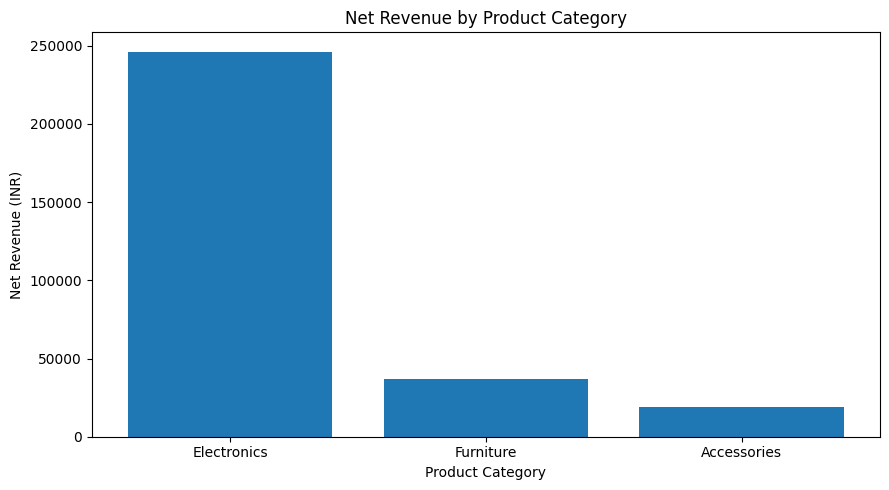

In [58]:
# Import the visualisation library
import matplotlib.pyplot as plt

# Create a folder to store project charts
CHART_DIR = os.path.join(
    PROJECT_DIR,
    "05_Screenshots",
    "Charts"
)

os.makedirs(CHART_DIR, exist_ok=True)

# Read the Gold category revenue dataset
category_chart_df = spark.read.parquet(
    os.path.join(GOLD_DIR, "revenue_by_category")
)

# Convert the small aggregated dataset to Pandas
category_chart_pd = category_chart_df.toPandas()

# Create the bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    category_chart_pd["category"],
    category_chart_pd["total_net_revenue"]
)

plt.title("Net Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Net Revenue (INR)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()

# Save the chart
plt.savefig(
    os.path.join(CHART_DIR, "revenue_by_category.png"),
    dpi=300
)

# Display the chart
plt.show()

### 20.1 Product-wise Revenue Visualisation

A product-wise revenue chart compares the total net revenue generated by individual products. It helps identify the products contributing the most to overall sales.

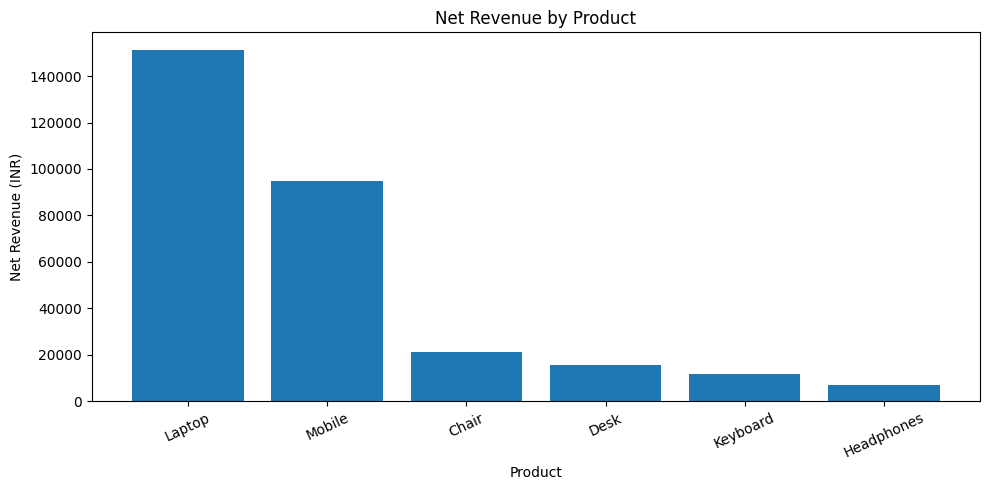

In [59]:
# Read the Gold product revenue dataset
product_chart_df = spark.read.parquet(
    os.path.join(GOLD_DIR, "revenue_by_product")
)

# Convert the aggregated data to Pandas
product_chart_pd = product_chart_df.toPandas()

# Sort products by revenue
product_chart_pd = product_chart_pd.sort_values(
    by="total_net_revenue",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(10, 5))

plt.bar(
    product_chart_pd["product_name"],
    product_chart_pd["total_net_revenue"]
)

plt.title("Net Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Net Revenue (INR)")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=25)
plt.tight_layout()

# Save the chart
plt.savefig(
    os.path.join(CHART_DIR, "revenue_by_product.png"),
    dpi=300
)

# Display the chart
plt.show()

### 20.2 City-wise Revenue Visualisation

City-wise revenue analysis compares the net revenue generated by customers from different geographical locations. This visualisation helps identify the cities contributing the most revenue in the synthetic e-commerce dataset.

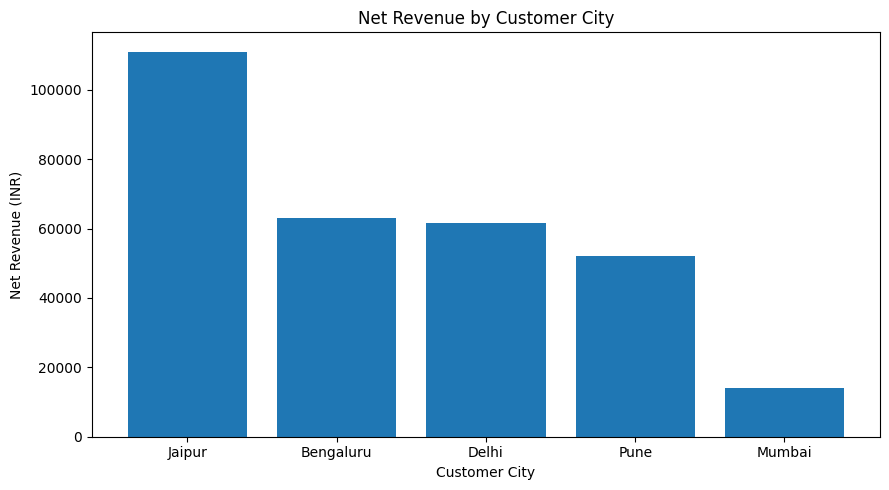

In [60]:
# Read the Gold city revenue dataset
city_chart_df = spark.read.parquet(
    os.path.join(GOLD_DIR, "revenue_by_city")
)

# Convert the aggregated data to Pandas
city_chart_pd = city_chart_df.toPandas()

# Sort cities by revenue
city_chart_pd = city_chart_pd.sort_values(
    by="total_net_revenue",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    city_chart_pd["city"],
    city_chart_pd["total_net_revenue"]
)

plt.title("Net Revenue by Customer City")
plt.xlabel("Customer City")
plt.ylabel("Net Revenue (INR)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()

# Save the chart
plt.savefig(
    os.path.join(CHART_DIR, "revenue_by_city.png"),
    dpi=300
)

# Display the chart
plt.show()

### 20.3 Order Status Distribution

Order status analysis examines the distribution of orders across different processing stages. It helps understand how many orders are placed, shipped and delivered at the time represented by the dataset.

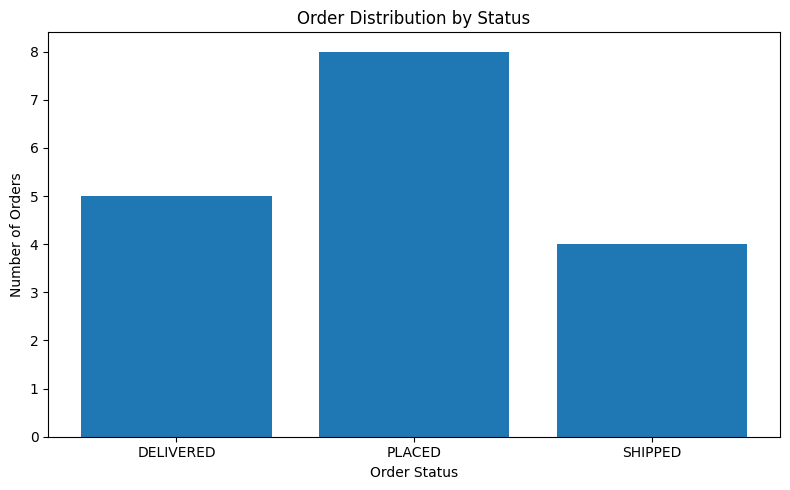

In [61]:
# Read the Gold order status dataset
status_chart_df = spark.read.parquet(
    os.path.join(GOLD_DIR, "orders_by_status")
)

# Convert the aggregated data to Pandas
status_chart_pd = status_chart_df.toPandas()

# Create the bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    status_chart_pd["status"],
    status_chart_pd["number_of_orders"]
)

plt.title("Order Distribution by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.tight_layout()

# Save the chart
plt.savefig(
    os.path.join(CHART_DIR, "orders_by_status.png"),
    dpi=300
)

# Display the chart
plt.show()

### 20.4 Daily Sales Trend Visualisation

Daily sales analysis presents the net revenue generated on each order date. A line chart is used to display changes in sales over time and identify variations in the dataset.

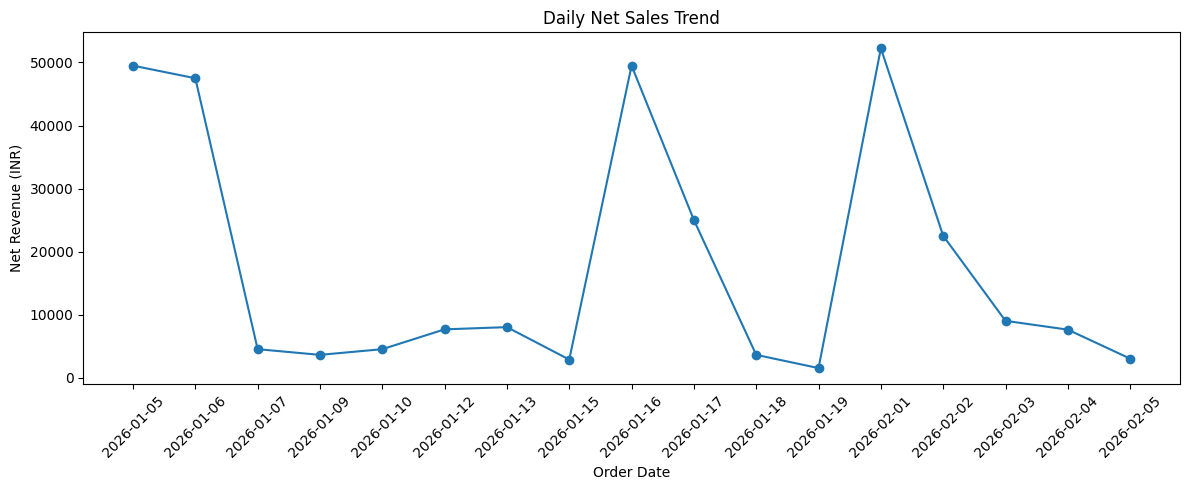

In [62]:
# Read the Gold daily sales dataset
daily_chart_df = spark.read.parquet(
    os.path.join(GOLD_DIR, "daily_sales")
)

# Convert the aggregated data to Pandas
daily_chart_pd = daily_chart_df.toPandas()

# Sort records by date
daily_chart_pd = daily_chart_pd.sort_values(
    by="order_date"
)

# Create the line chart
plt.figure(figsize=(12, 5))

plt.plot(
    daily_chart_pd["order_date"].astype(str),
    daily_chart_pd["total_net_revenue"],
    marker="o"
)

plt.title("Daily Net Sales Trend")
plt.xlabel("Order Date")
plt.ylabel("Net Revenue (INR)")
plt.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=45)
plt.tight_layout()

# Save the chart
plt.savefig(
    os.path.join(CHART_DIR, "daily_sales_trend.png"),
    dpi=300
)

# Display the chart
plt.show()

In [63]:
# List all saved chart files
chart_files = sorted(os.listdir(CHART_DIR))

print("SAVED PROJECT VISUALISATIONS")
print("--------------------------------")

for filename in chart_files:
    print(filename)

print("--------------------------------")
print("Total charts saved:", len(chart_files))

SAVED PROJECT VISUALISATIONS
--------------------------------
daily_sales_trend.png
orders_by_status.png
revenue_by_category.png
revenue_by_city.png
revenue_by_product.png
--------------------------------
Total charts saved: 5


### 21. Consolidated Project Results

The project results are consolidated to summarise the outputs of data ingestion, data cleaning, analytical processing, incremental ETL and data-quality validation.

The summary provides an overview of the implemented pipeline and its execution results.

In [64]:
# Define the project results
project_results = [
    ("Source Data", "Customers", "6"),
    ("Source Data", "Products", "6"),
    ("Source Data", "Batch 1 Orders", "17"),
    ("Source Data", "Batch 2 Orders", "8"),
    ("Bronze Layer", "Total source records", "37"),
    ("Silver Layer", "Valid customers", "6"),
    ("Silver Layer", "Valid products", "6"),
    ("Silver Layer", "Valid orders", "17"),
    ("Silver Layer", "Rejected orders", "4"),
    ("Gold Layer", "Analytical datasets", "6"),
    ("Incremental ETL", "New orders inserted", "5"),
    ("Incremental ETL", "Existing orders updated", "3"),
    ("Incremental ETL", "Unchanged orders retained", "9"),
    ("Incremental ETL", "Final orders", "17"),
    ("Validation", "Duplicate order IDs", "0"),
    ("Validation", "Missing mandatory values", "0"),
    ("Validation", "Unknown customer references", "0"),
    ("Validation", "Unknown product references", "0"),
    ("Validation", "Full refresh vs incremental differences", "0"),
    ("Visualisation", "Charts generated", "5")
]

# Create a Spark DataFrame
results_summary_df = spark.createDataFrame(
    project_results,
    ["project_stage", "result_metric", "result_value"]
)

# Display the consolidated results
results_summary_df.show(
    n=30,
    truncate=False
)

# Save the summary in the Control directory
SUMMARY_PATH = os.path.join(
    PROJECT_DIR,
    "03_Data_Lake",
    "Control",
    "project_results_summary"
)

results_summary_df.write \
    .mode("overwrite") \
    .parquet(SUMMARY_PATH)

print("Project results summary saved successfully.")

+---------------+---------------------------------------+------------+
|project_stage  |result_metric                          |result_value|
+---------------+---------------------------------------+------------+
|Source Data    |Customers                              |6           |
|Source Data    |Products                               |6           |
|Source Data    |Batch 1 Orders                         |17          |
|Source Data    |Batch 2 Orders                         |8           |
|Bronze Layer   |Total source records                   |37          |
|Silver Layer   |Valid customers                        |6           |
|Silver Layer   |Valid products                         |6           |
|Silver Layer   |Valid orders                           |17          |
|Silver Layer   |Rejected orders                        |4           |
|Gold Layer     |Analytical datasets                    |6           |
|Incremental ETL|New orders inserted                    |5           |
|Incre

### 22. Project Directory Organisation

The project files are organised into separate directories for notebooks, raw data, the Medallion Data Lake, reports, screenshots and GitHub resources.

This directory structure improves project organisation, maintainability and reproducibility.

In [65]:
# Display the project directory structure
for root, dirs, files in os.walk(PROJECT_DIR):

    # Calculate the folder level
    level = root.replace(PROJECT_DIR, "").count(os.sep)

    # Indent folder names according to their level
    indent = "    " * level

    print(indent + os.path.basename(root) + "/")

    # Display files in the current folder
    for filename in files:
        print(indent + "    " + filename)

Big Data Final Project/
    01_Notebooks/
        Big_Data_Final_Project_Neha.ipynb
    04_Reports/
        Big_Data_Project_Theory_and_Viva_Notes.docx.gdoc
    02_Data/
        Raw/
            customers.csv
            products.csv
            orders_batch_1.csv
            orders_batch_2.csv
    03_Data_Lake/
        Bronze/
            customers/
                part-00000-25bc4874-59d7-411d-a098-eedad0fb6289-c000.snappy.parquet
                .part-00000-25bc4874-59d7-411d-a098-eedad0fb6289-c000.snappy.parquet.crc
                _SUCCESS
                ._SUCCESS.crc
            products/
                part-00000-5a94f39e-0847-4914-bb43-501343f973e4-c000.snappy.parquet
                .part-00000-5a94f39e-0847-4914-bb43-501343f973e4-c000.snappy.parquet.crc
                _SUCCESS
                ._SUCCESS.crc
            orders_batch_1/
                part-00000-fa1e78c6-d04f-49d3-9dea-c3b413cf582a-c000.snappy.parquet
                .part-00000-fa1e78c6-d04f-49d3-9dea-c3b41

In [66]:
# Check important project deliverable paths
important_paths = {
    "Project Notebook": os.path.join(
        PROJECT_DIR, "01_Notebooks",
        "Big_Data_Final_Project_Neha.ipynb"
    ),
    "Reports Folder": os.path.join(PROJECT_DIR, "04_Reports"),
    "Screenshots Folder": os.path.join(PROJECT_DIR, "05_Screenshots"),
    "GitHub Folder": os.path.join(PROJECT_DIR, "06_GitHub")
}

for name, path in important_paths.items():
    print(
        name,
        ":",
        "EXISTS" if os.path.exists(path) else "MISSING"
    )

Project Notebook : EXISTS
Reports Folder : EXISTS
Screenshots Folder : EXISTS
GitHub Folder : EXISTS


### 23. Proposed System Architecture

The proposed system follows a Medallion Data Lake architecture implemented using Apache Spark. Source data is ingested into the Bronze layer, cleaned and validated in the Silver layer, and transformed into analytical datasets in the Gold layer.

An incremental ETL workflow processes incoming batches by identifying new and updated records. Control datasets maintain snapshots and audit information. The Gold datasets are used to generate visualisations for analytical interpretation.

In [67]:
# Install Graphviz support
!apt-get -qq install graphviz

# Import the Graphviz library
from graphviz import Digraph

# Create a directed architecture diagram
architecture = Digraph(
    "Big_Data_Pipeline",
    format="png"
)

architecture.attr(
    rankdir="TB",
    label="PySpark-Based Medallion Data Lake and Incremental ETL Pipeline",
    labelloc="t",
    fontsize="18"
)

architecture.attr("node", shape="box", style="rounded,filled")

# Define architecture components
architecture.node("source", "Source Data\nCustomers | Products\nOrders Batch 1 | Orders Batch 2",
                  fillcolor="lightblue")

architecture.node("bronze", "BRONZE LAYER\nRaw Data Ingestion\nParquet Storage",
                  fillcolor="lightblue")

architecture.node("silver", "SILVER LAYER\nData Cleaning\nValidation | Deduplication\nRejected Records",
                  fillcolor="lightgreen")

architecture.node("gold", "GOLD LAYER\nRevenue Analytics\nProduct | Category | City\nStatus | Daily Sales",
                  fillcolor="plum")

architecture.node("visual", "Analytics and Visualisation\nFive Charts",
                  fillcolor="lightyellow")

architecture.node("control", "Incremental ETL and Control\nNew Records | Updates\nSnapshots | Audit Log",
                  fillcolor="mistyrose")

# Connect the main pipeline
architecture.edge("source", "bronze")
architecture.edge("bronze", "silver")
architecture.edge("silver", "gold")
architecture.edge("gold", "visual")

# Connect incremental control to the Silver processing stage
architecture.edge("control", "silver", label="Batch processing")

# Render and save the diagram
architecture_path = os.path.join(
    CHART_DIR,
    "project_architecture"
)

architecture.render(
    architecture_path,
    cleanup=True
)

print("Architecture diagram saved successfully.")

Architecture diagram saved successfully.


### 23.1 Pipeline Execution Workflow

The pipeline execution workflow describes the sequence of processing activities, beginning with source data ingestion and ending with analytical output generation.

The workflow includes source validation, Bronze storage, Silver transformations, Gold analytics, incremental batch processing and final quality verification.

In [68]:
# Create a directed workflow diagram
workflow = Digraph(
    "Pipeline_Workflow",
    format="png"
)

workflow.attr(
    rankdir="TB",
    label="Data Pipeline Execution Workflow",
    labelloc="t",
    fontsize="18"
)

workflow.attr("node", shape="box", style="rounded,filled")

# Define workflow stages
workflow.node("start", "Start", shape="oval", fillcolor="lightgrey")

workflow.node("extract", "Extract Source CSV Files",
              fillcolor="lightblue")

workflow.node("bronze", "Load into Bronze Layer",
              fillcolor="lightblue")

workflow.node("clean", "Clean and Standardise Data",
              fillcolor="lightgreen")

workflow.node("validate", "Validate Records",
              fillcolor="lightgreen")

workflow.node("reject", "Store Invalid Records",
              fillcolor="mistyrose")

workflow.node("silver", "Create Clean Silver Datasets",
              fillcolor="lightgreen")

workflow.node("incremental", "Process New and Updated Batches",
              fillcolor="lightyellow")

workflow.node("gold", "Generate Gold Analytics",
              fillcolor="plum")

workflow.node("visual", "Generate Charts and Reports",
              fillcolor="lightyellow")

workflow.node("end", "End", shape="oval", fillcolor="lightgrey")

# Connect workflow stages
workflow.edge("start", "extract")
workflow.edge("extract", "bronze")
workflow.edge("bronze", "clean")
workflow.edge("clean", "validate")
workflow.edge("validate", "reject", label="Invalid records")
workflow.edge("validate", "silver", label="Valid records")
workflow.edge("silver", "incremental")
workflow.edge("incremental", "gold")
workflow.edge("gold", "visual")
workflow.edge("visual", "end")

# Save the workflow diagram
workflow_path = os.path.join(
    CHART_DIR,
    "pipeline_workflow"
)

workflow.render(
    workflow_path,
    cleanup=True
)

print("Pipeline workflow diagram saved successfully.")

Pipeline workflow diagram saved successfully.


In [69]:
# List all generated visual assets
visual_files = sorted(os.listdir(CHART_DIR))

print("PROJECT VISUAL ASSETS")
print("------------------------------")

for filename in visual_files:
    if filename.endswith(".png"):
        print(filename)

print("------------------------------")
print("Total visual assets:", len([
    f for f in visual_files if f.endswith(".png")
]))

PROJECT VISUAL ASSETS
------------------------------
daily_sales_trend.png
orders_by_status.png
pipeline_workflow.png
project_architecture.png
revenue_by_category.png
revenue_by_city.png
revenue_by_product.png
------------------------------
Total visual assets: 7


### 24. Project Limitations

The project demonstrates a PySpark-based Medallion Data Lake and incremental ETL pipeline using a synthetic e-commerce dataset. However, certain limitations should be considered:

1. **Dataset size:** The project uses a small synthetic dataset containing six customers, six products and two order batches. It demonstrates the processing logic but does not establish performance on large real-world datasets.

2. **Execution environment:** Apache Spark runs in local mode within Google Colab. The project does not evaluate execution across a multi-node distributed cluster.

3. **Incremental storage:** Incremental processing is implemented using Spark DataFrames and Parquet snapshots. Transactional merge capabilities of technologies such as Delta Lake, Apache Iceberg or Apache Hudi are not implemented.

4. **Data realism:** The e-commerce records are synthetically generated for demonstration. The analytical findings should not be interpreted as actual business or market trends.

5. **Automation:** The pipeline is executed through notebook cells rather than a production scheduling and orchestration platform.

### 24.1 Future Scope

The project can be extended by using larger real-world datasets, deploying Spark on a distributed cloud environment, implementing transactional incremental updates through Delta Lake or Apache Iceberg, and introducing automated scheduling and monitoring. Further extensions may include real-time ingestion using Apache Kafka and more advanced data-quality monitoring.